# B2 — Pembentukan Citra dan Ruang Warna

Evaluasi Praktikum P1–P4 Computer Vision
SIMUTEH — Klasifikasi Kualitas Daun Teh

# 2.1 Hitung Manual


In [1]:
   import sys, os, time
   import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
   sys.path.append("../src")
   from utils_cv import baca, tampil, kontras_bercak, statistik

   DATA_DIR = "../data/sintetis"
   HASIL_DIR = "../hasil"
   os.makedirs(HASIL_DIR, exist_ok=True)

In [2]:
# DATA PERHITUNGAN
f = 4.0          # panjang fokus (mm)
pitch = 0.0014   # ukuran piksel sensor (mm)
X = 5.0          # diameter bercak (mm)
Z = 300.0        # jarak kamera (mm)

# a. Ukuran bayangan bercak pada sensor
x = (f * X) / Z
pixel = x / pitch

print("a. Jarak 300 mm")
print(f"Ukuran bayangan sensor : {x:.4f} mm")
print(f"Diameter bercak        : {pixel:.2f} piksel")

# b. Jarak kamera 600 mm
Z2 = 600.0
x2 = (f * X) / Z2
pixel2 = x2 / pitch

print("\nb. Jarak 600 mm")
print(f"Ukuran bayangan sensor : {x2:.4f} mm")
print(f"Diameter bercak        : {pixel2:.2f} piksel")

# c. Jarak maksimum agar bercak minimal 10 piksel
Z_max = (f * X) / (10 * pitch)

print("\nc. Jarak maksimum")
print(f"{Z_max:.2f} mm")

# d. Setelah resize menjadi lebar 640 piksel
faktor_resize = 640 / 4000
pixel_resize = pixel * faktor_resize
Z_max_resize = Z_max * faktor_resize

print("\nd. Setelah resize")
print(f"Diameter bercak : {pixel_resize:.2f} piksel")
print(f"Jarak maksimum  : {Z_max_resize:.2f} mm")

a. Jarak 300 mm
Ukuran bayangan sensor : 0.0667 mm
Diameter bercak        : 47.62 piksel

b. Jarak 600 mm
Ukuran bayangan sensor : 0.0333 mm
Diameter bercak        : 23.81 piksel

c. Jarak maksimum
1428.57 mm

d. Setelah resize
Diameter bercak : 7.62 piksel
Jarak maksimum  : 228.57 mm


In [3]:
# Perhitungan ukuran memori citra tanpa kompresi

# Foto asli: 4000 x 3000, RGB 8 bit
memori_asli = 4000 * 3000 * 3
memori_warna = 640 * 480 * 3
memori_gray = 640 * 480 * 1

# Total 300 foto asli
total_300 = memori_asli * 300

print("Ukuran memori foto asli :", memori_asli / 1_000_000, "MB")
print("Ukuran citra 640x480 RGB:", memori_warna / 1_000_000, "MB")
print("Ukuran citra 640x480 Gray:", memori_gray / 1_000_000, "MB")
print("Total 300 foto asli      :", total_300 / 1_000_000_000, "GB")

Ukuran memori foto asli : 36.0 MB
Ukuran citra 640x480 RGB: 0.9216 MB
Ukuran citra 640x480 Gray: 0.3072 MB
Total 300 foto asli      : 10.8 GB


In [4]:
# Warna piksel bercak dan daun sehat dalam RGB
bercak_rgb = np.uint8([[[196, 178, 86]]])
daun_rgb = np.uint8([[[52, 136, 60]]])

# Konversi RGB ke BGR untuk OpenCV
bercak_bgr = cv2.cvtColor(bercak_rgb, cv2.COLOR_RGB2BGR)
daun_bgr = cv2.cvtColor(daun_rgb, cv2.COLOR_RGB2BGR)

# Konversi ke grayscale
bercak_gray = cv2.cvtColor(bercak_bgr, cv2.COLOR_BGR2GRAY)
daun_gray = cv2.cvtColor(daun_bgr, cv2.COLOR_BGR2GRAY)

# Konversi ke HSV
bercak_hsv = cv2.cvtColor(bercak_bgr, cv2.COLOR_BGR2HSV)
daun_hsv = cv2.cvtColor(daun_bgr, cv2.COLOR_BGR2HSV)

print("Nilai grayscale bercak:", int(bercak_gray[0, 0]))
print("Nilai grayscale daun sehat:", int(daun_gray[0, 0]))
print("Selisih grayscale:", abs(int(bercak_gray[0, 0]) - int(daun_gray[0, 0])))

print("\nHue bercak:", int(bercak_hsv[0, 0, 0]))
print("Hue daun sehat:", int(daun_hsv[0, 0, 0]))

Nilai grayscale bercak: 173
Nilai grayscale daun sehat: 102
Selisih grayscale: 71

Hue bercak: 25
Hue daun sehat: 63


# 2.2 Rencana Akuisisi

In [5]:
import pandas as pd

# Tabel rencana akuisisi citra
rencana_akuisisi = [
    ["Jarak pemotretan", "Maksimal 22,86 cm dari daun"],
    ["Sudut pemotretan", "Tegak lurus terhadap permukaan daun (90 derajat)"],
    ["Resolusi minimum", "4000 x 3000 piksel"],
    ["Alas/background", "Alas polos dengan warna kontras terhadap daun"],
    ["Acuan ukuran", "Penggaris diletakkan di samping daun sebagai skala"],
    ["Kondisi cahaya", "Normal, gelap, terang, kontras rendah, dan bayangan"],
    ["Jumlah citra", "20 citra per kelas, yaitu kelas ringan dan berat"],
    ["Penamaan file", "teh_001.png, teh_002.png, dan seterusnya"],
    ["Izin pengambilan", "Meminta persetujuan pemilik kebun atau pihak terkait"],
    ["Metadata EXIF", "Menghapus metadata EXIF sebelum citra dibagikan"],
    ["Privasi", "Tidak memasukkan wajah atau informasi pribadi ke dalam foto"]
]

df_akuisisi = pd.DataFrame(
    rencana_akuisisi,
    columns=["Aspek", "Rencana Akuisisi"]
)

display(df_akuisisi)

,Aspek,Rencana Akuisisi
0,Jarak pemotretan,"Maksimal 22,86 cm dari daun"
1,Sudut pemotretan,Tegak lurus terhadap permukaan daun (90 derajat)
2,Resolusi minimum,4000 x 3000 piksel
3,Alas/background,Alas polos dengan warna kontras terhadap daun
4,Acuan ukuran,Penggaris diletakkan di samping daun sebagai s...
5,Kondisi cahaya,"Normal, gelap, terang, kontras rendah, dan bay..."
6,Jumlah citra,"20 citra per kelas, yaitu kelas ringan dan berat"
7,Penamaan file,"teh_001.png, teh_002.png, dan seterusnya"
8,Izin pengambilan,Meminta persetujuan pemilik kebun atau pihak t...
9,Metadata EXIF,Menghapus metadata EXIF sebelum citra dibagikan


# 2.3 Kanal Warna

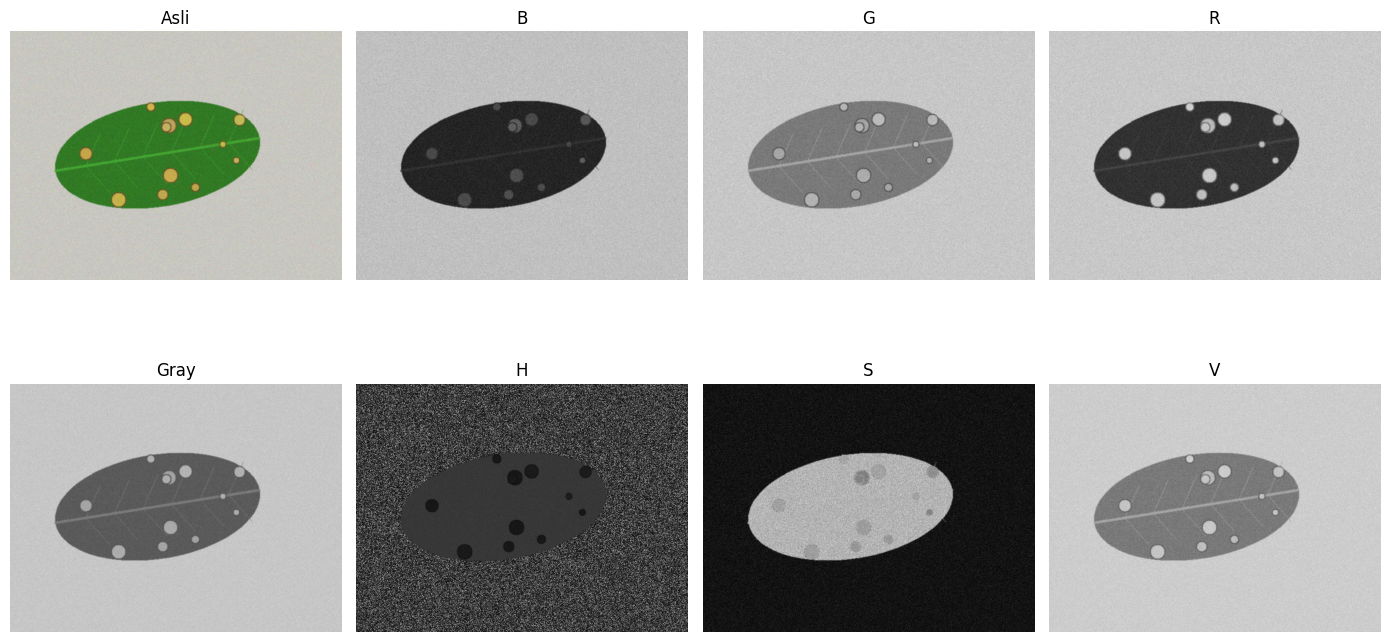

Nilai Kontras Bercak (KB)
KB kanal B   : 3.02
KB kanal G   : 2.17
KB kanal R   : 11.72
KB kanal Gray: 6.26
KB kanal H   : 8.18
KB kanal S   : 1.39
KB kanal V   : 3.99


In [6]:
# Membaca citra dan mask
nama = "teh_041.png"

img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

# Konversi ke grayscale dan HSV
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Pemisahan kanal
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

# Menyimpan seluruh kanal
kanal = {
    "B": b,
    "G": g,
    "R": r,
    "Gray": gray,
    "H": h,
    "S": s,
    "V": v
}

# Menampilkan citra asli dan kanal
judul = ["Asli"] + list(kanal.keys())
gambar = [img] + list(kanal.values())

plt.figure(figsize=(14, 8))

for i, (nama_kanal, citra) in enumerate(zip(judul, gambar)):
    plt.subplot(2, 4, i + 1)

    if nama_kanal == "Asli":
        plt.imshow(cv2.cvtColor(citra, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(citra, cmap="gray", vmin=0, vmax=255)

    plt.title(nama_kanal)
    plt.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b2_panel_kanal.png"), dpi=150, bbox_inches="tight")
plt.show()

# Menghitung kontras bercak setiap kanal
print("Nilai Kontras Bercak (KB)")

for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

# 2.4 Eksperimen Sampling dan Kuantisasi

fx=0.5: ukuran=(240, 320), KB=6.66
fx=0.2: ukuran=(96, 128), KB=5.03
fx=0.1: ukuran=(48, 64), KB=3.01
fx=0.05: ukuran=(24, 32), KB=1.38


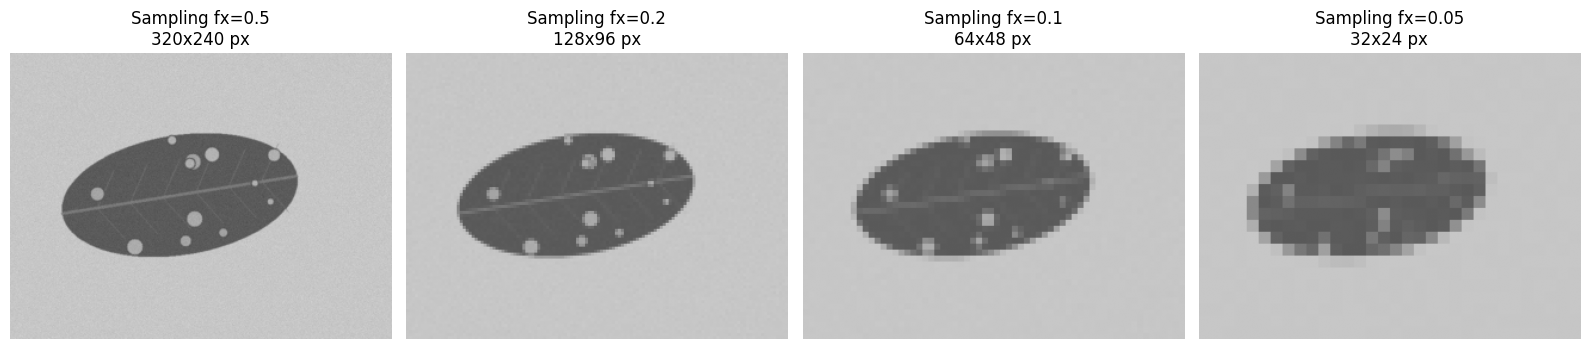

     fx   ukuran    KB
0  0.50  320x240  6.66
1  0.20   128x96  5.03
2  0.10    64x48  3.01
3  0.05    32x24  1.38


In [7]:
# Eksperimen sampling
hasil_sampling = []

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, fx in enumerate([0.5, 0.2, 0.1, 0.05]):

    # Perkecil citra
    kecil = cv2.resize(
        gray, None,
        fx=fx, fy=fx,
        interpolation=cv2.INTER_AREA
    )

    # Perbesar kembali ke ukuran semula
    besar = cv2.resize(
        kecil,
        gray.shape[::-1],
        interpolation=cv2.INTER_NEAREST
    )

    # Hitung kontras bercak
    kb = kontras_bercak(besar, md, mb)

    print(f"fx={fx}: ukuran={kecil.shape}, KB={kb:.2f}")
    hasil_sampling.append([fx, f"{kecil.shape[1]}x{kecil.shape[0]}", round(kb, 2)])

    # Tampilkan citra
    axes[i].imshow(besar, cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(f"Sampling fx={fx}\n{kecil.shape[1]}x{kecil.shape[0]} px")
    axes[i].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b2_sampling.png"), dpi=150, bbox_inches="tight")
plt.show()

# Simpan tabel sampling untuk laporan
tabel_sampling = pd.DataFrame(hasil_sampling, columns=["fx", "ukuran", "KB"])
print(tabel_sampling)
tabel_sampling.to_csv(os.path.join(HASIL_DIR, "b2_tabel_sampling.csv"), index=False)

k=1: 2 level, KB=9.10
k=2: 3 level, KB=9.11
k=3: 5 level, KB=4.11
k=4: 10 level, KB=5.68
k=8: 153 level, KB=6.26


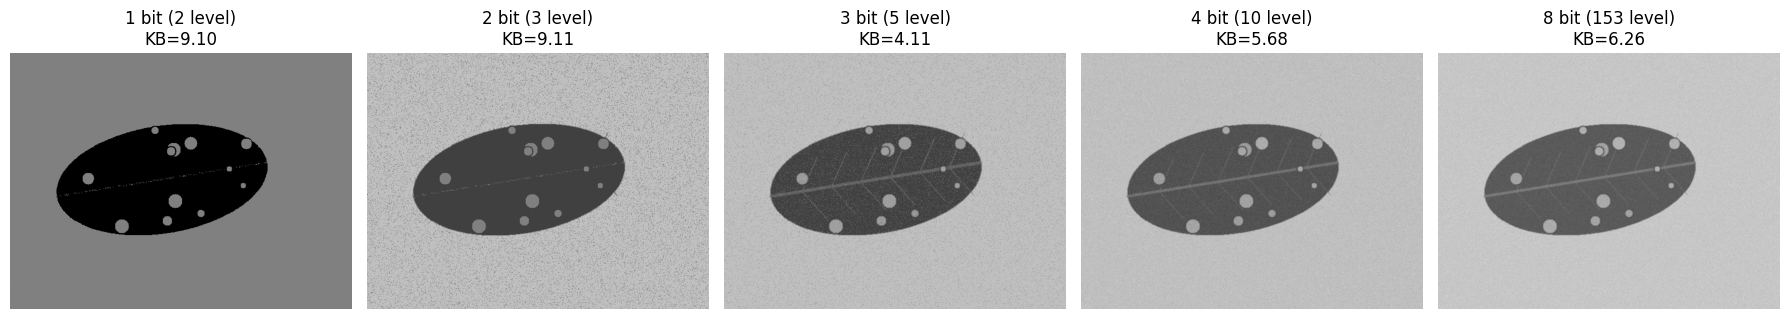

   bit  jumlah_level    KB
0    1             2  9.10
1    2             3  9.11
2    3             5  4.11
3    4            10  5.68
4    8           153  6.26


In [8]:
# Eksperimen kuantisasi
hasil_kuantisasi = []

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i, k in enumerate([1, 2, 3, 4, 8]):

    # Sisakan k bit
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah

    # Hitung jumlah level dan kontras bercak
    level = len(np.unique(kuant))
    kb = kontras_bercak(kuant, md, mb)

    print(f"k={k}: {level} level, KB={kb:.2f}")
    hasil_kuantisasi.append([k, level, round(kb, 2)])

    # Tampilkan citra
    axes[i].imshow(kuant, cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(f"{k} bit ({level} level)\nKB={kb:.2f}")
    axes[i].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b2_kuantisasi.png"), dpi=150, bbox_inches="tight")
plt.show()

# Simpan tabel kuantisasi untuk laporan
tabel_kuantisasi = pd.DataFrame(hasil_kuantisasi, columns=["bit", "jumlah_level", "KB"])
print(tabel_kuantisasi)
tabel_kuantisasi.to_csv(os.path.join(HASIL_DIR, "b2_tabel_kuantisasi.csv"), index=False)

# 2.5 Uji di seluruh kondisi cahaya

In [9]:
# Fungsi untuk memisahkan seluruh kanal warna
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {
        "B": b,
        "G": g,
        "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h,
        "S": s,
        "V": v
    }


# Membaca data label
label = pd.read_csv(os.path.join(DATA_DIR, "label.csv"))

baris = []

# Memproses 20 citra kelas berat
for _, d in label[label["kelas"] == "berat"].iterrows():

    nama = d["nama_file"]

    # Membaca citra dan mask
    img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
    md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
    mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

    # Memastikan seluruh file berhasil dibaca
    if img is None or md is None or mb is None:
        print(f"File tidak ditemukan: {nama}")
        continue

    # Menghitung KB setiap kanal
    kb = {
        k: kontras_bercak(c, md, mb)
        for k, c in semua_kanal(img).items()
    }

    # Menambahkan kondisi cahaya
    kb["kondisi"] = d["kondisi_cahaya"]

    baris.append(kb)


# Menghitung rata-rata KB berdasarkan kondisi cahaya
tabel_kb = (
    pd.DataFrame(baris)
    .groupby("kondisi")
    .mean(numeric_only=True)
    .round(2)
)

# Menampilkan hasil Tabel 8
print(tabel_kb)

# Menyimpan hasil
tabel_kb.to_csv(os.path.join(HASIL_DIR, "b2_kb_kanal.csv"))

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.22  0.59   4.88  1.76  4.08  0.76  1.11
gelap           1.49  1.56  10.16  4.83  5.31  0.85  3.71
kontras_rendah  1.00  0.62   3.98  2.40  1.89  0.30  1.60
normal          2.72  1.07   8.97  4.55  6.73  1.64  2.64
terang          1.91  0.70   6.93  3.65  5.40  0.84  1.88


# 2.6

In [10]:
# Memilih 20 citra kelas ringan
data_ringan = label[label["kelas"] == "ringan"]

baris_ringan = []

# Menghitung KB pada seluruh kanal
for _, d in data_ringan.iterrows():
    nama = d["nama_file"]

    img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
    md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
    mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

    if img is None or md is None or mb is None:
        print(f"File tidak ditemukan: {nama}")
        continue

    kb = {
        k: kontras_bercak(c, md, mb)
        for k, c in semua_kanal(img).items()
    }

    kb["kondisi"] = d["kondisi_cahaya"]
    baris_ringan.append(kb)

# Menghitung rerata KB berdasarkan kondisi cahaya
urutan_kondisi = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

tabel_kb_ringan = (
    pd.DataFrame(baris_ringan)
    .groupby("kondisi")
    .mean(numeric_only=True)
    .reindex(urutan_kondisi)
    .round(2)
)

print(tabel_kb_ringan)
tabel_kb_ringan.to_csv(os.path.join(HASIL_DIR, "b2_kb_kanal_ringan.csv"))

                   B     G     R  Gray     H     S     V
kondisi                                                 
normal          1.63  0.75  8.70  2.85  8.34  1.57  1.08
gelap           1.05  0.70  8.89  2.70  6.50  1.14  1.71
terang          1.41  0.67  6.14  2.81  5.30  0.77  1.33
kontras_rendah  1.03  0.31  3.96  1.66  2.72  0.69  0.71
bayangan        0.53  0.77  3.30  0.42  4.43  0.68  0.36



Citra: teh_021.png
KB semua kanal: {'B': np.float64(0.51), 'G': np.float64(0.46), 'R': np.float64(5.47), 'Gray': np.float64(2.63), 'H': np.float64(3.71), 'S': np.float64(0.13), 'V': np.float64(1.77)}
Kanal terbaik: R (KB = 5.47)

Citra: teh_045.png
KB semua kanal: {'B': np.float64(1.49), 'G': np.float64(1.08), 'R': np.float64(4.98), 'Gray': np.float64(2.45), 'H': np.float64(2.76), 'S': np.float64(0.65), 'V': np.float64(1.67)}
Kanal terbaik: R (KB = 4.98)


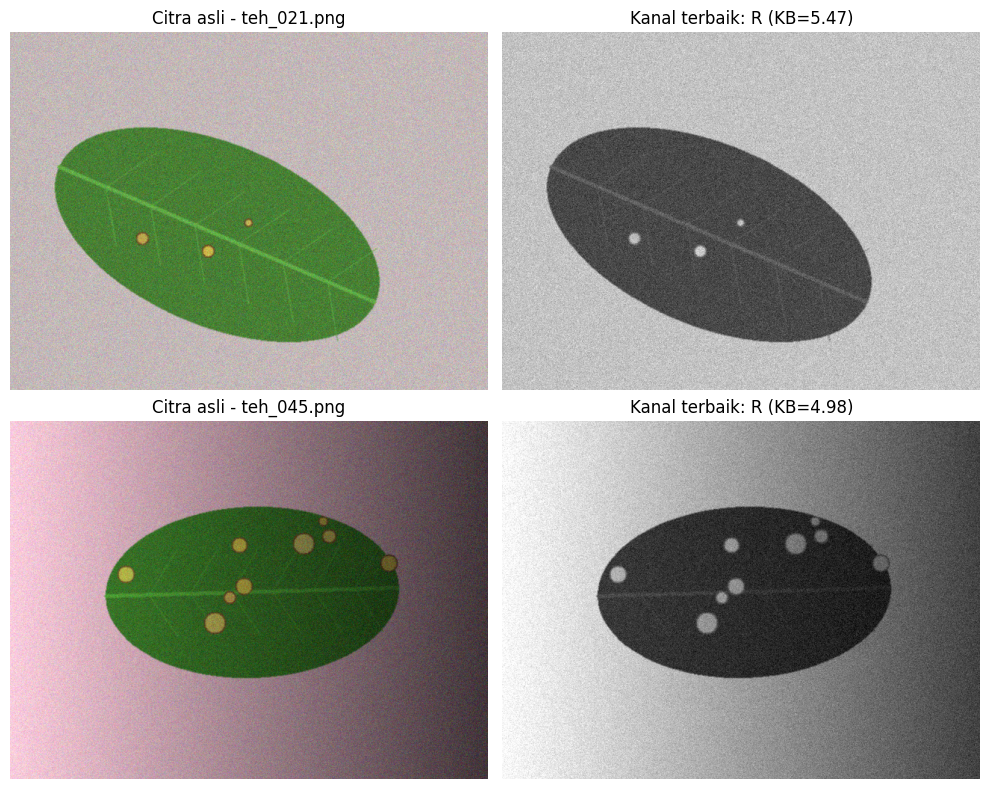

In [11]:
# Menentukan kanal terbaik untuk setiap citra
daftar_citra = ["teh_021.png", "teh_045.png"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for i, nama in enumerate(daftar_citra):
    # Membaca citra dan mask
    img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
    md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
    mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

    # Memisahkan seluruh kanal
    kanal = semua_kanal(img)

    # Menghitung KB setiap kanal
    hasil_kb = {
        k: kontras_bercak(c, md, mb)
        for k, c in kanal.items()
    }

    # Menentukan kanal dengan KB tertinggi
    kanal_terbaik = max(hasil_kb, key=hasil_kb.get)

    print(f"\nCitra: {nama}")
    print("KB semua kanal:", {k: round(v, 2) for k, v in hasil_kb.items()})
    print(f"Kanal terbaik: {kanal_terbaik} (KB = {hasil_kb[kanal_terbaik]:.2f})")

    # Citra asli
    axes[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"Citra asli - {nama}")
    axes[i, 0].axis("off")

    # Kanal terbaik
    axes[i, 1].imshow(kanal[kanal_terbaik], cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(f"Kanal terbaik: {kanal_terbaik} (KB={hasil_kb[kanal_terbaik]:.2f})")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b2_kanal_terbaik_021_045.png"), dpi=150, bbox_inches="tight")
plt.show()

# Kesimpulan Pengamatan
Kanal R menjadi kanal terbaik pada kedua citra, baik kelas ringan maupun kelas berat. Hal ini menunjukkan bahwa kanal yang unggul dalam menonjolkan bercak pada kelas berat juga mampu memperlihatkan bercak kecil pada kelas ringan. Dengan demikian, kanal R berpotensi digunakan untuk membantu membedakan bercak daun teh pada kondisi pencahayaan yang berbeda.